# Stream B: Statistical Comparison of the Strategies

**Master's Thesis Project:** Seasonality-Aware Drift Detection System  
**Stream B, week 5:** are the differences between the adaptation strategies larger than the variation between series? The means of the earlier notebooks hide how consistent a difference is from one series to the next. Here every series is a block and every strategy a treatment, and the strategies are compared with the rank tests recommended by Demsar (2006) for many methods on many data sets: the Friedman test with the Nemenyi post-hoc test for the whole set, and the paired Wilcoxon signed-rank test with the Holm correction for the comparisons behind the claims of the thesis.

The results are computed by `python -m src.recommendations.run_backtest` (reference, gated and advised strategies, and the strategies on detector alarms) and read here from `data/processed/stream_b/runs.csv`; the tests are in `src/recommendations/stats_tests.py`.

In [1]:
# Import required libraries
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.recommendations.plots import label_of
from src.recommendations.stats_tests import critical_difference, friedman, plot_cd, tagged, wide, wilcoxon_pairs

RESULTS = "../data/processed/stream_b"
runs = pd.read_csv(f"{RESULTS}/runs.csv", float_precision="round_trip")
runs["name"] = tagged(runs)

DETECTORS = ("adwin", "profile_conformal")
CALENDAR = ["nothing", "always", "scheduled", "scheduled_gate", "catalog_gate", "rules", "rules_gate"]
ON_ALARM = [f"{s} [{d}]" for s in ("alarm_retrain", "alarm_gate", "alarm_catalog_gate", "alarm_rules", "alarm_rules_gate")
            for d in DETECTORS]
MAIN = CALENDAR + ON_ALARM
REFERENCE = ["naive", "oracle_weekly", "oracle"] + [f"alarm_oracle [{d}]" for d in DETECTORS]

# group -> (rows of runs.csv, metric); on the control series there is no change, so the error after deployment is used
GROUPS = {
    "ENTSO-E": (runs.source == "entsoe", "mase_post"),
    "seismic noise": (runs.source == "seismic", "mase_post"),
    "real series": (runs.source.isin(["entsoe", "seismic"]), "mase_post"),
    "synthetic: level shift": ((runs.source == "synthetic") & (runs.scenario == "level_shift"), "mase_post"),
    "synthetic: ramp": ((runs.source == "synthetic") & (runs.scenario == "trend_ramp"), "mase_post"),
    "synthetic: noise x2": ((runs.source == "synthetic") & (runs.scenario == "variance"), "mase_post"),
    "synthetic: no change": ((runs.source == "synthetic") & (runs.scenario == "none"), "mase_all"),
}
print(f"{runs.groupby(['source', 'series', 'scenario']).ngroups} series, {len(runs)} runs, "
      f"{len(MAIN)} strategies in the ranking, {len(REFERENCE)} references")

263 series, 5786 runs, 17 strategies in the ranking, 5 references


## 1. Method

Per series the strategies are ranked by their error, rank 1 for the lowest MASE; strategies with the same error share the average rank. Ranks make series of different sources and scales comparable, so the national load and the seismic noise can also be pooled into one group of real series.

* **Friedman test:** if all strategies were equally good, their average ranks would be close to (k + 1) / 2. The statistic grows with the spread of the average ranks (with the usual correction for ties); Demsar recommends its Iman-Davenport F form, which is less conservative.
* **Nemenyi test:** after a rejection, two strategies differ significantly if their average ranks differ by at least the critical difference CD = q_alpha * sqrt(k (k + 1) / (6 N)) (alpha = 0.05, k strategies, N series). CD grows with k and shrinks with N: with 17 strategies it is 8.7 ranks on the 8 countries, 5.2 on the 23 real series and 3.2 on 60 synthetic series.
* **Wilcoxon signed-rank test:** for a chosen pair, the per-series differences of MASE are ranked by size and the ranks of the positive and negative differences are compared. It uses the size of the differences and is stronger than Nemenyi for a single pair. Zero differences (the same forecasts on a series) are split between the two signs. The pairs tested on one group form one family and get the Holm correction.

With 8 series the smallest possible two-sided p value of the Wilcoxon test is 2 / 2^8 = 0.0078, so after the Holm correction over the pairs no single comparison on the national load alone can reach 0.05; the pooled real series carry the tests on real data.

## 2. Strategies in the Ranking

The ranking contains every deployable strategy that was run: the seven weekly or daily strategies and the five strategies on alarm with each of the two stand-in detectors, 17 in all. Taking all of them, instead of a selection made after seeing the results, keeps the post-hoc test honest. The hindsight oracles (`oracle_weekly`, `oracle`, `alarm_oracle`) use future data and cannot be deployed, and the seasonal naive forecast is a benchmark of the base model, not an adaptation strategy; they are reported separately as references. The weekly oracle also enters one paired comparison, as the ceiling for the best checked action.

In [2]:
pd.DataFrame([(s, label_of(s), "ranking" if s in MAIN else "reference") for s in MAIN + REFERENCE],
             columns=["strategy", "description", "role"])

,strategy,description,role
0,nothing,do nothing,ranking
1,always,always retrain (daily),ranking
2,scheduled,scheduled (weekly),ranking
3,scheduled_gate,scheduled + backtest check,ranking
4,catalog_gate,best checked action (weekly),ranking
5,rules,"rules, no check",ranking
6,rules_gate,rules + backtest check,ranking
7,alarm_retrain [adwin],retrain on alarm (adwin),ranking
8,alarm_retrain [profile_conformal],retrain on alarm (profile_conformal),ranking
9,alarm_gate [adwin],alarm + backtest check (adwin),ranking


## 3. Friedman Test per Group

`N` series, `k` strategies; `chi2` and `p` of the Friedman test, `F_F` and `p_F` of its Iman-Davenport form, and the Nemenyi critical difference `CD` at alpha = 0.05.

In [3]:
tables, tests = {}, {}
for group, (rows, metric) in GROUPS.items():
    tables[group] = wide(runs[rows], MAIN, metric)
    tests[group] = friedman(tables[group])
    tests[group]["cd"] = critical_difference(tests[group]["k"], tests[group]["n"])
pd.DataFrame([dict(group=g, metric=GROUPS[g][1], N=t["n"], k=t["k"], chi2=round(t["chi2"], 1), p=f"{t['p']:.1e}",
                   F_F=round(t["ff"], 1), p_F=f"{t['p_ff']:.1e}", CD=round(t["cd"], 2)) for g, t in tests.items()])

,group,metric,N,k,chi2,p,F_F,p_F,CD
0,ENTSO-E,mase_post,8,17,76.5,7.1e-10,10.4,1.2e-15,8.73
1,seismic noise,mase_post,15,17,100.9,2.3e-14,10.2,4.2e-19,6.38
2,real series,mase_post,23,17,159.3,1.1e-25,16.8,1.6e-34,5.15
3,synthetic: level shift,mase_post,60,17,498.7,6.1e-96,63.8,6.4e-138,3.19
4,synthetic: ramp,mase_post,60,17,561.6,3.2e-109,83.2,1.4e-167,3.19
5,synthetic: noise x2,mase_post,60,17,461.9,3.5e-88,54.7,2.0e-122,3.19
6,synthetic: no change,mase_all,60,17,721.9,2.8e-143,178.9,2.4e-272,3.19


## 4. Average Ranks and Cost

Average rank of each strategy per group (1 = best), with the mean retrainings per series in brackets, since the thesis trades error against the number of model changes. Within a group, strategies whose average ranks differ by less than `CD` are not significantly different by the Nemenyi test.

In [4]:
retrains = {g: runs[rows].groupby("name").retrains.mean() for g, (rows, _) in GROUPS.items()}
ranks = pd.DataFrame({g: t["ranks"] for g, t in tests.items()})
shown = ranks.copy().astype(object)
for g in ranks:
    shown[g] = [f"{r:.2f} ({retrains[g][s]:.1f})" for s, r in ranks[g].items()]
shown.loc[ranks["real series"].sort_values().index]

,ENTSO-E,seismic noise,real series,synthetic: level shift,synthetic: ramp,synthetic: noise x2,synthetic: no change
name,,,,,,,
always,1.00 (174.0),1.00 (83.0),1.00 (114.7),1.00 (97.0),1.03 (97.0),9.53 (97.0),3.27 (97.0)
scheduled,4.50 (24.0),2.73 (11.0),3.35 (15.5),3.28 (13.0),2.23 (13.0),8.20 (13.0),3.00 (13.0)
alarm_retrain [adwin],5.12 (18.4),6.20 (4.4),5.83 (9.3),5.51 (6.1),5.27 (6.0),6.97 (5.5),5.42 (4.7)
scheduled_gate,5.62 (3.4),6.77 (2.9),6.37 (3.1),6.26 (2.9),6.78 (3.3),6.91 (1.0),6.09 (2.0)
catalog_gate,8.75 (6.0),7.23 (4.1),7.76 (4.8),6.06 (4.3),5.89 (4.2),6.10 (2.2),4.52 (2.7)
alarm_gate [adwin],5.44 (2.6),9.00 (1.4),7.76 (1.8),9.37 (1.7),9.70 (1.7),7.68 (0.3),9.72 (0.8)
alarm_retrain [profile_conformal],8.00 (4.5),9.53 (3.0),9.00 (3.5),7.62 (4.5),7.97 (4.5),6.38 (5.6),4.58 (4.4)
alarm_catalog_gate [profile_conformal],8.81 (1.4),10.33 (1.1),9.80 (1.2),10.71 (1.7),10.41 (1.6),5.94 (0.9),6.32 (1.2)
alarm_catalog_gate [adwin],8.62 (4.5),10.57 (1.8),9.89 (2.7),9.21 (2.2),10.01 (2.0),6.92 (1.0),8.23 (1.1)


In [5]:
# per group: the best strategy and those not significantly worse than it (rank difference below CD)
rows = []
for g, t in tests.items():
    r = t["ranks"].sort_values()
    close = [s for s, v in r.items() if v - r.iloc[0] < t["cd"]]
    rows.append(dict(group=g, best=r.index[0], best_rank=round(r.iloc[0], 2), CD=round(t["cd"], 2),
                     not_significantly_worse=", ".join(close[1:])))
pd.DataFrame(rows)

,group,best,best_rank,CD,not_significantly_worse
0,ENTSO-E,always,1.00,8.73,"scheduled, alarm_retrain [adwin], alarm_gate [..."
1,seismic noise,always,1.00,6.38,"scheduled, alarm_retrain [adwin], scheduled_ga..."
2,real series,always,1.00,5.15,"scheduled, alarm_retrain [adwin]"
3,synthetic: level shift,always,1.00,3.19,scheduled
4,synthetic: ramp,always,1.03,3.19,scheduled
5,synthetic: noise x2,alarm_catalog_gate [profile_conformal],5.94,3.19,"catalog_gate, alarm_retrain [profile_conformal..."
6,synthetic: no change,scheduled,3.00,3.19,"always, catalog_gate, alarm_retrain [profile_c..."


## 5. Critical Difference Diagrams

Average ranks on the axis (best on the left); a thick bar joins strategies whose average ranks differ by less than the critical difference, which is drawn above the axis.

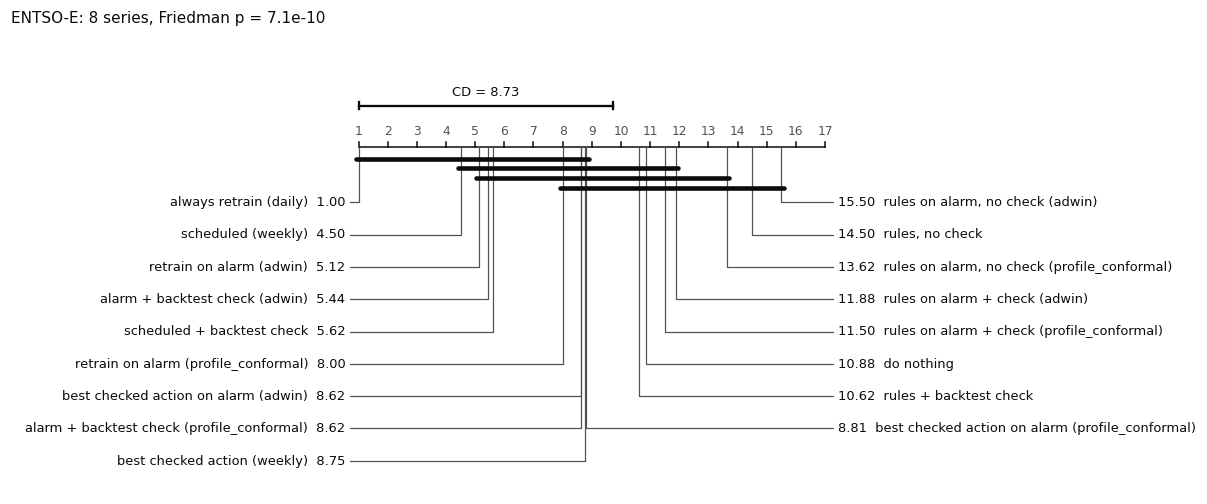

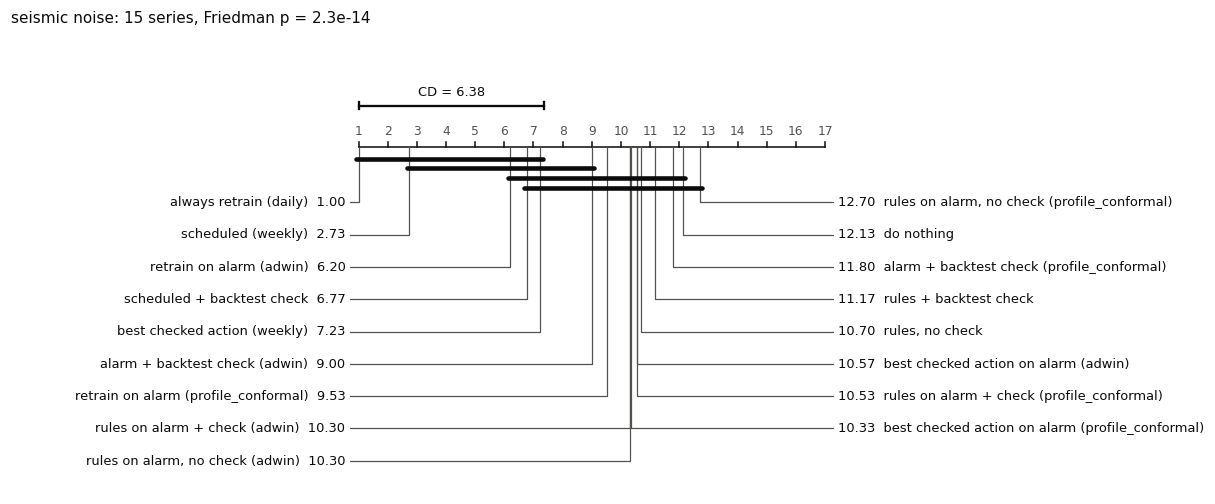

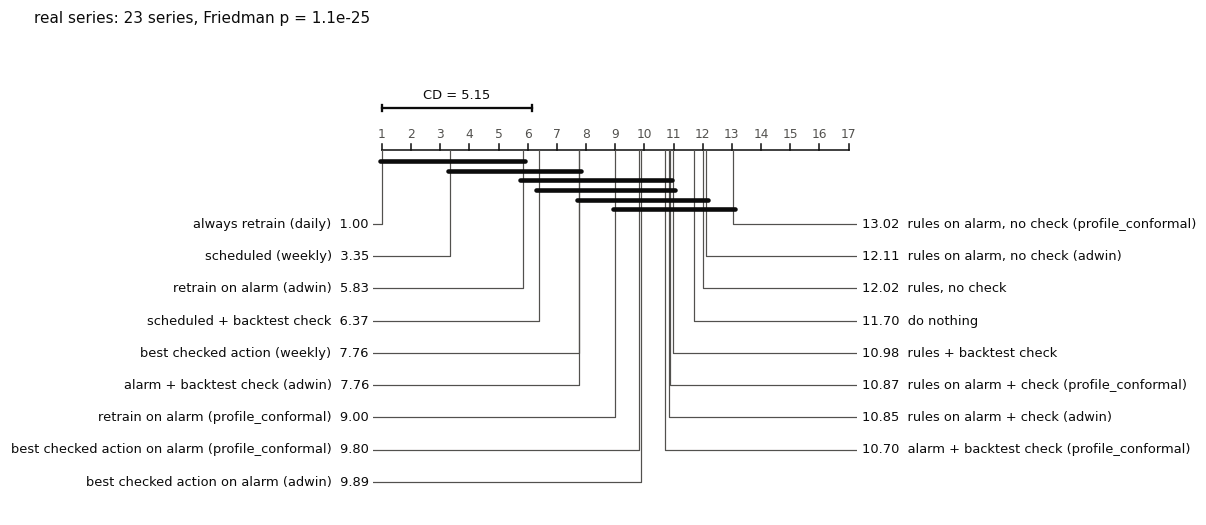

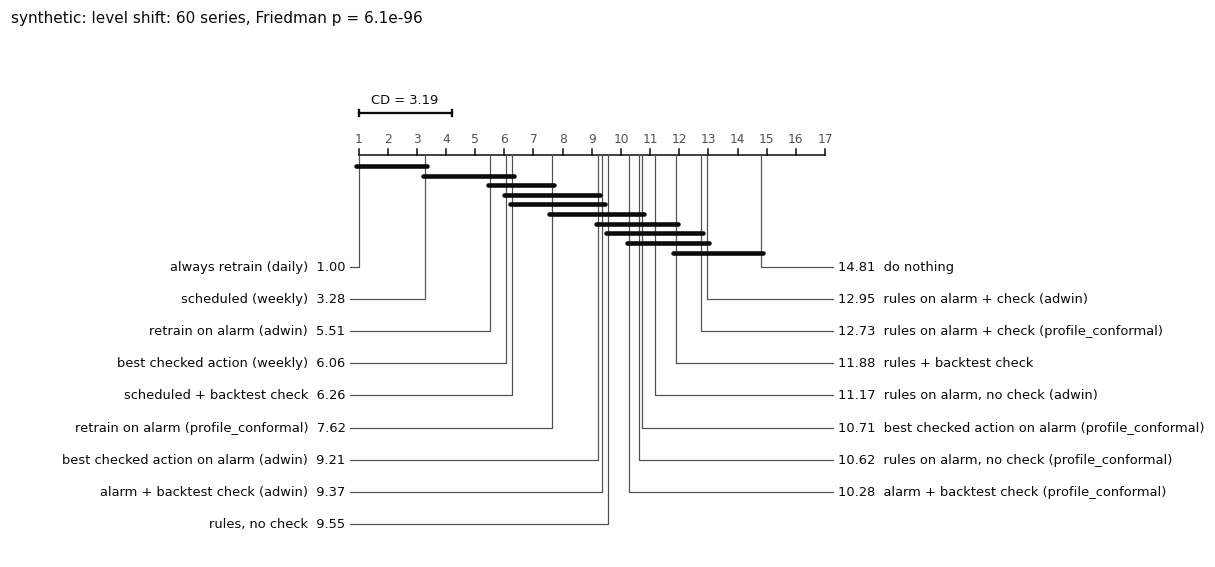

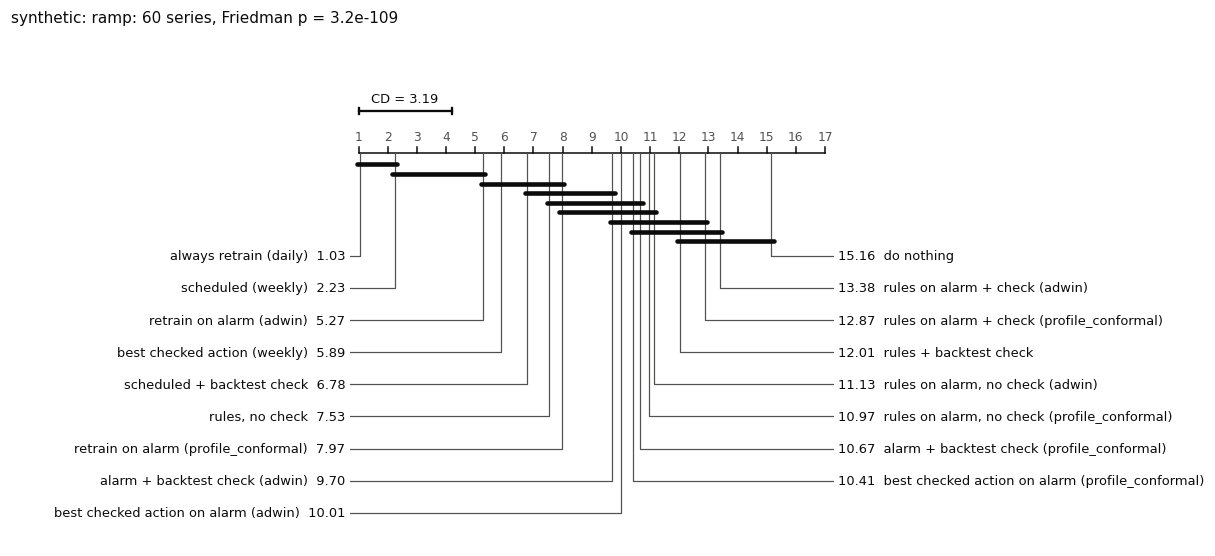

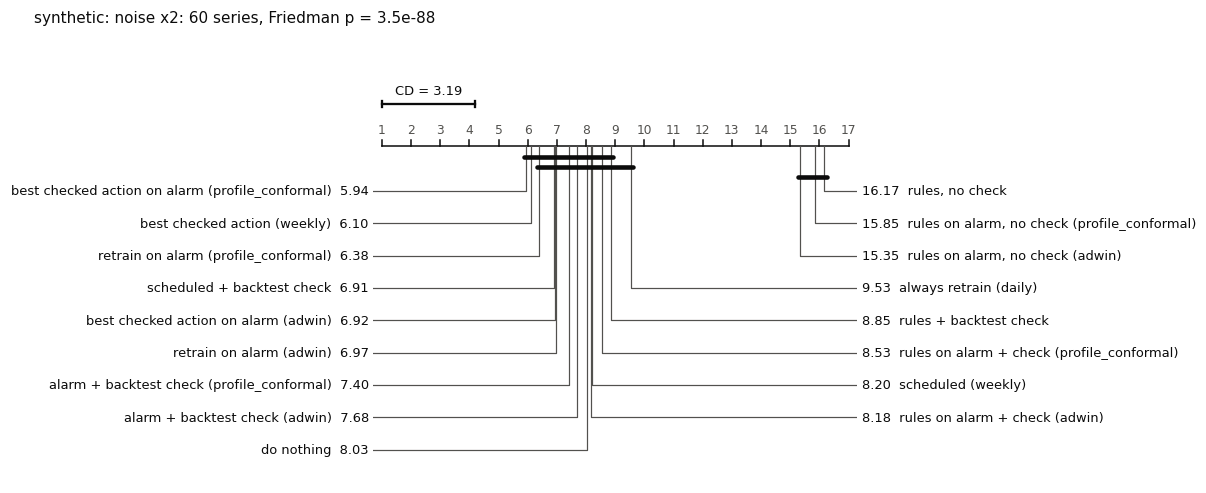

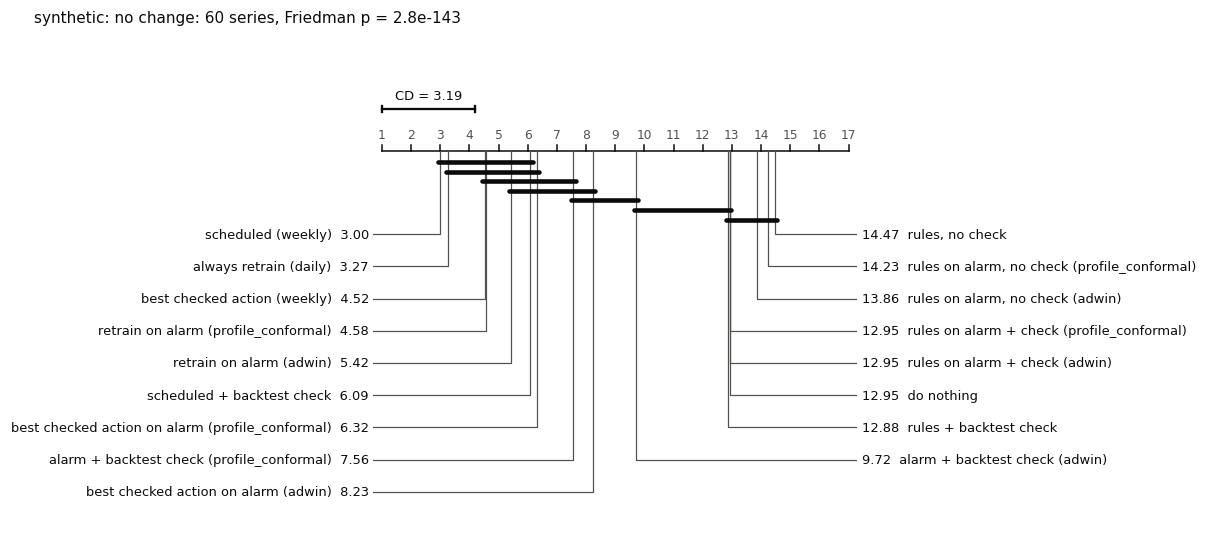

In [6]:
for group in GROUPS:
    t = tests[group]
    fig = plot_cd(t["ranks"], t["cd"], f"{group}: {t['n']} series, Friedman p = {t['p']:.1e}", label=label_of)
    plt.show()

## 6. Paired Comparisons

The comparisons behind the claims of the thesis, as a minus b: `wins` counts the series on which a has the lower error, `median_diff` is the median of the differences of MASE (negative: a is better). `p_holm` is corrected over the pairs of the group.

* `scheduled_gate` vs `scheduled`: what the acceptance rule costs in error on the weekly schedule;
* `rules_gate` vs `rules`, `rules` vs `nothing`, `rules_gate` vs `nothing`: whether advice without the check does harm and whether the check removes it;
* `catalog_gate` vs `scheduled`: the best checked action against plain retraining;
* `always` vs `scheduled`: daily against weekly retraining;
* `alarm_retrain` vs `scheduled` for each detector: retraining on alarm against the calendar;
* `catalog_gate` vs `oracle_weekly`: the room between the best checked action and the hindsight ceiling.

In [7]:
PAIRS = [("scheduled_gate", "scheduled"), ("rules_gate", "rules"), ("rules", "nothing"), ("rules_gate", "nothing"),
         ("catalog_gate", "scheduled"), ("always", "scheduled"), ("alarm_retrain [adwin]", "scheduled"),
         ("alarm_retrain [profile_conformal]", "scheduled"), ("catalog_gate", "oracle_weekly")]
pairs = []
for group, (rows, metric) in GROUPS.items():
    w = wilcoxon_pairs(tables[group], PAIRS, extra=wide(runs[rows], REFERENCE, metric))
    pairs.append(w.assign(group=group))
pairs = pd.concat(pairs, ignore_index=True)
pairs["significant"] = pairs.p_holm < 0.05
fmt = pairs.assign(p=pairs.p.map("{:.1e}".format), p_holm=pairs.p_holm.map("{:.1e}".format))
for group in GROUPS:
    print(group)
    display(fmt[fmt.group == group][["a", "b", "n", "mean_a", "mean_b", "median_diff", "wins", "ties", "losses", "p", "p_holm",
                                     "significant"]].round(3).reset_index(drop=True))

ENTSO-E


,a,b,n,mean_a,mean_b,median_diff,wins,ties,losses,p,p_holm,significant
0,scheduled_gate,scheduled,8,0.717,0.696,0.024,2,0,6,3.9e-02,2.0e-01,False
1,rules_gate,rules,8,0.780,0.974,-0.162,6,1,1,3.1e-02,1.9e-01,False
2,rules,nothing,8,0.974,0.787,0.132,2,0,6,3.9e-02,2.0e-01,False
3,rules_gate,nothing,8,0.780,0.787,0.000,2,4,2,7.5e-01,7.5e-01,False
4,catalog_gate,scheduled,8,0.738,0.696,0.049,0,0,8,7.8e-03,7.0e-02,False
5,always,scheduled,8,0.650,0.696,-0.044,8,0,0,7.8e-03,7.0e-02,False
6,alarm_retrain [adwin],scheduled,8,0.709,0.696,0.012,2,0,6,1.5e-01,3.0e-01,False
7,alarm_retrain [profile_conformal],scheduled,8,0.751,0.696,0.049,2,0,6,3.9e-02,2.0e-01,False
8,catalog_gate,oracle_weekly,8,0.738,0.607,0.131,0,0,8,7.8e-03,7.0e-02,False


seismic noise


,a,b,n,mean_a,mean_b,median_diff,wins,ties,losses,p,p_holm,significant
0,scheduled_gate,scheduled,15,1.092,0.998,0.051,0,0,15,6.1e-05,5.5e-04,True
1,rules_gate,rules,15,1.300,1.204,0.030,3,3,9,1.2e-01,3.7e-01,False
2,rules,nothing,15,1.204,1.449,-0.016,9,0,6,5.2e-01,1.0e+00,False
3,rules_gate,nothing,15,1.300,1.449,0.000,6,5,4,5.1e-01,1.0e+00,False
4,catalog_gate,scheduled,15,1.089,0.998,0.060,1,0,14,4.3e-04,1.7e-03,True
5,always,scheduled,15,0.921,0.998,-0.050,15,0,0,6.1e-05,5.5e-04,True
6,alarm_retrain [adwin],scheduled,15,1.084,0.998,0.039,1,0,14,3.1e-04,1.5e-03,True
7,alarm_retrain [profile_conformal],scheduled,15,1.176,0.998,0.076,1,0,14,1.2e-04,7.3e-04,True
8,catalog_gate,oracle_weekly,15,1.089,0.885,0.152,0,0,15,6.1e-05,5.5e-04,True


real series


,a,b,n,mean_a,mean_b,median_diff,wins,ties,losses,p,p_holm,significant
0,scheduled_gate,scheduled,23,0.962,0.893,0.040,2,0,21,2.4e-06,1.7e-05,True
1,rules_gate,rules,23,1.119,1.124,0.000,9,4,10,8.8e-01,1.0e+00,False
2,rules,nothing,23,1.124,1.219,0.044,11,0,12,5.4e-01,1.0e+00,False
3,rules_gate,nothing,23,1.119,1.219,0.000,8,9,6,5.1e-01,1.0e+00,False
4,catalog_gate,scheduled,23,0.967,0.893,0.050,1,0,22,2.4e-06,1.7e-05,True
5,always,scheduled,23,0.827,0.893,-0.049,23,0,0,2.4e-07,2.1e-06,True
6,alarm_retrain [adwin],scheduled,23,0.953,0.893,0.027,3,0,20,6.0e-05,2.4e-04,True
7,alarm_retrain [profile_conformal],scheduled,23,1.028,0.893,0.064,3,0,20,6.0e-06,3.0e-05,True
8,catalog_gate,oracle_weekly,23,0.967,0.788,0.131,0,0,23,2.4e-07,2.1e-06,True


... (4 outputs left out)

synthetic: noise x2


,a,b,n,mean_a,mean_b,median_diff,wins,ties,losses,p,p_holm,significant
0,scheduled_gate,scheduled,60,1.665,1.673,-0.002,32,0,28,4.5e-02,1.8e-01,False
1,rules_gate,rules,60,1.675,1.873,-0.177,59,0,1,1.7e-11,1.5e-10,True
2,rules,nothing,60,1.873,1.669,0.180,0,0,60,1.6e-11,1.5e-10,True
3,rules_gate,nothing,60,1.675,1.669,0.000,1,52,7,1.6e-01,2.0e-01,False
4,catalog_gate,scheduled,60,1.660,1.673,-0.007,34,0,26,1.4e-02,6.8e-02,False
5,always,scheduled,60,1.677,1.673,0.003,27,0,33,7.7e-02,2.0e-01,False
6,alarm_retrain [adwin],scheduled,60,1.670,1.673,-0.005,37,0,23,6.6e-02,2.0e-01,False
7,alarm_retrain [profile_conformal],scheduled,60,1.665,1.673,-0.006,43,0,17,4.3e-04,2.6e-03,True
8,catalog_gate,oracle_weekly,60,1.660,1.611,0.052,5,0,55,8.0e-11,5.6e-10,True


synthetic: no change


,a,b,n,mean_a,mean_b,median_diff,wins,ties,losses,p,p_holm,significant
0,scheduled_gate,scheduled,60,0.885,0.877,0.009,5,0,55,1.4e-10,1.1e-09,True
1,rules_gate,rules,60,0.904,0.937,0.000,22,38,0,3.5e-05,2.4e-04,True
2,rules,nothing,60,0.937,0.904,0.000,0,38,22,3.5e-05,2.4e-04,True
3,rules_gate,nothing,60,0.904,0.904,0.000,1,59,0,8.0e-01,1.0e+00,False
4,catalog_gate,scheduled,60,0.880,0.877,0.004,21,0,39,2.2e-02,6.5e-02,False
5,always,scheduled,60,0.876,0.877,-0.000,30,0,30,9.4e-01,1.0e+00,False
6,alarm_retrain [adwin],scheduled,60,0.883,0.877,0.004,16,0,44,4.4e-05,2.4e-04,True
7,alarm_retrain [profile_conformal],scheduled,60,0.880,0.877,0.003,15,0,45,8.1e-04,3.2e-03,True
8,catalog_gate,oracle_weekly,60,0.880,0.847,0.033,0,0,60,1.6e-11,1.5e-10,True


## 7. Reference Strategies

Mean error of the references per group, next to the best deployable strategy of the ranking. The oracles bound what a policy with the same catalog and the same review times can reach; their distance to the deployable strategies is the room for a better advisor.

In [8]:
ref, best = {}, {}
for group, (rows, metric) in GROUPS.items():
    r = wide(runs[rows], REFERENCE, metric).mean()
    best[group] = tests[group]["ranks"].idxmin()
    r["best deployable (lowest average rank)"] = tables[group][best[group]].mean()
    ref[group] = r
display(pd.DataFrame(ref).round(3))
print("Best deployable strategy per group:", "; ".join(f"{g}: {s}" for g, s in best.items()))

,ENTSO-E,seismic noise,real series,synthetic: level shift,synthetic: ramp,synthetic: noise x2,synthetic: no change
name,,,,,,,
naive,1.025,1.112,1.082,1.121,1.094,1.996,0.985
oracle_weekly,0.607,0.885,0.788,1.021,0.955,1.611,0.847
oracle,0.486,0.757,0.663,0.893,0.870,1.533,0.791
alarm_oracle [adwin],0.636,0.982,0.862,1.077,1.035,1.635,0.874
alarm_oracle [profile_conformal],0.748,1.077,0.962,1.126,1.114,1.631,0.871
best deployable (lowest average rank),0.650,0.921,0.827,1.004,0.980,1.659,0.877


Best deployable strategy per group: ENTSO-E: always; seismic noise: always; real series: always; synthetic: level shift: always; synthetic: ramp: always; synthetic: noise x2: alarm_catalog_gate [profile_conformal]; synthetic: no change: scheduled


## 8. Findings

* **The ranking is not chance.** The Friedman test rejects equal average ranks in every group (p below 1e-9 even on the 8 countries).
* **Daily retraining is the most accurate strategy after a change of the level** (average rank 1.00 on the national load, the seismic noise and the synthetic level shift: the best on every series), at 83 to 174 retrainings per series. On the 23 real series the Nemenyi test cannot separate it from the weekly schedule and from retraining on ADWIN alarms, but the paired test shows that it beats the weekly schedule on all 23 series. When the noise doubles it ranks 14th of 17 and is significantly worse than the best strategy there.
* **The acceptance rule costs some accuracy after a change and saves most retrainings.** The checked schedule is worse than the plain schedule on 21 of the 23 real series and on 51 of the 60 level shifts (significant after Holm), with 73% to 92% fewer retrainings. When the noise doubles the two are not significantly different, while the checked schedule retrains 92% less. On the control series the checked schedule is worse on 55 of 60 series, by a median of 0.009: the gain of retraining on new data that it forgoes.
* **The check removes the harm of a poor advisor.** When the noise doubles, the rules without the check are worse than doing nothing on all 60 series, and the three strategies with unchecked rules are the three worst of the ranking; the checked rules are not significantly different from doing nothing (52 ties). On the real series neither the rules nor the checked rules differ significantly from doing nothing: the rules are worse on 6 of the 8 countries but better on 9 of the 15 stations. Where the rules help, after the synthetic level shift and ramp, the check takes away part of their gain (the checked rules are worse on 46 and 47 of 60 series).
* **Retraining on alarm is significantly less accurate than the weekly schedule on the real series** (worse on 20 of 23 series with each detector), with fewer retrainings; when the noise doubles, retraining on the conformal alarms is slightly better than the schedule (43 of 60 series, median difference 0.006).
* **The best checked action stays far from the weekly oracle:** the oracle is better on 258 of the 263 series and on all 23 real series, by a median of 0.13 MASE there. The weekly oracle chooses greedily with a one-week lookahead, so it is not a strict ceiling: daily retraining beats it on 51 series (43 of them after the synthetic level shift) and some checked strategies beat it on up to 6 series; the daily oracle is never beaten.
* **The national load alone is too small for paired tests after the correction** (8 series: the smallest Holm-adjusted p value is 0.07); its paired results point the same way as on the seismic noise, and the pooled group of real series carries the tests on real data.